#### 1. Подготовка данных

Количество отсчетов: 12960
Пропусков (NaN или нулевых значений): 1
Выбросов: 3
Медиана: 258.14
Оставшихся пропусков: 0


,время,было,стало
0,2018-11-01 04:14:00,4752.63,258.14
1,2018-11-01 04:18:00,0.00,258.14
2,2018-11-05 03:17:00,2086.39,258.14
3,2018-11-09 02:39:00,4563.22,258.14


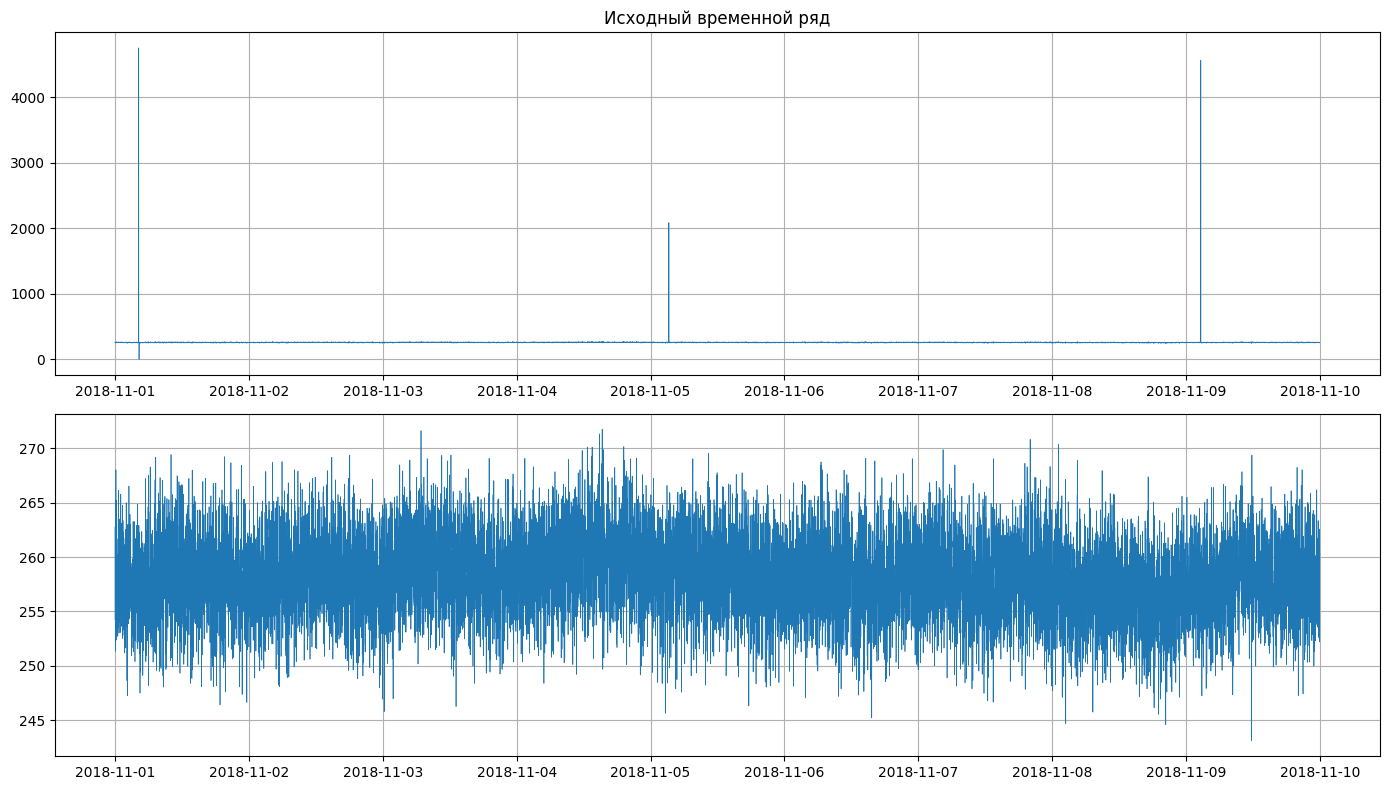

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data.txt", sep=";", skiprows=25, names=["start_date_time", "RCORR_E"])
df["start_date_time"] = pd.to_datetime(df["start_date_time"])
df["RCORR_E"] = pd.to_numeric(df["RCORR_E"], errors="coerce")
df = df.sort_values("start_date_time").set_index("start_date_time")

full_index = pd.date_range(df.index.min(), df.index.max(), freq="min")
df = df.reindex(full_index)
df.index.name = "start_date_time"

gaps_mask = df["RCORR_E"].isna() | (df["RCORR_E"] == 0)

valid = df.loc[~gaps_mask, "RCORR_E"]
mean_value = valid.mean()
std_value = valid.std()
lower_bound = mean_value - 3 * std_value
upper_bound = mean_value + 3 * std_value

outliers_mask = (df["RCORR_E"] < lower_bound) | (df["RCORR_E"] > upper_bound)
outliers_mask = outliers_mask & ~gaps_mask

clean_values = df.loc[~gaps_mask & ~outliers_mask, "RCORR_E"]
median_value = clean_values.median()

fixed_df = df.copy()
replace_mask = gaps_mask | outliers_mask
fixed_df.loc[replace_mask, "RCORR_E"] = median_value

print("Количество отсчетов:", len(df))
print("Пропусков (NaN или нулевых значений):", gaps_mask.sum())
print("Выбросов:", outliers_mask.sum())
print("Медиана:", round(median_value, 3))
print("Оставшихся пропусков:", fixed_df["RCORR_E"].isna().sum())

replaced = pd.DataFrame({
    "время": df.index[replace_mask],
    "было": df.loc[replace_mask, "RCORR_E"].values,
    "стало": fixed_df.loc[replace_mask, "RCORR_E"].values,
})
display(replaced)

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(df.index, df["RCORR_E"], linewidth=0.5)
axes[0].set_title("Исходный временной ряд")
axes[0].grid(True)

axes[1].plot(fixed_df.index, fixed_df["RCORR_E"], linewidth=0.5)
axes[1].grid(True)

plt.tight_layout()
plt.show()


#### 2. Векторы-истории

In [2]:
m = 180

values = fixed_df["RCORR_E"].to_numpy()
timestamps = fixed_df.index

n_vectors = len(values) // m
remainder = len(values) % m

values = values[remainder:]
timestamps = timestamps[remainder:]

vectors = values.reshape(n_vectors, m)
history_vectors = vectors[:-1]
test_vector = vectors[-1]

block_types = ["Исторический"] * (n_vectors - 1) + ["Тестовый"]
block_info = pd.DataFrame({
    "Номер вектора": np.arange(1, n_vectors + 1),
    "Начало": [timestamps[i * m] for i in range(n_vectors)],
    "Конец": [timestamps[(i + 1) * m - 1] for i in range(n_vectors)],
    "Тип": block_types,
})

print("Длина вектора m:", m)
print("Всего векторов:", n_vectors)
print("Размер исторических векторов:", history_vectors.shape)
print("Размер тестового вектора:", test_vector.shape)
print("Отброшено отсчетов в начале ряда:", remainder)
display(block_info.head())
display(block_info.tail())


Длина вектора m: 180
Всего векторов: 72
Размер исторических векторов: (71, 180)
Размер тестового вектора: (180,)
Отброшено отсчетов в начале ряда: 0


,Номер вектора,Начало,Конец,Тип
0,1,2018-11-01 00:00:00,2018-11-01 02:59:00,Исторический
1,2,2018-11-01 03:00:00,2018-11-01 05:59:00,Исторический
2,3,2018-11-01 06:00:00,2018-11-01 08:59:00,Исторический
3,4,2018-11-01 09:00:00,2018-11-01 11:59:00,Исторический
4,5,2018-11-01 12:00:00,2018-11-01 14:59:00,Исторический


,Номер вектора,Начало,Конец,Тип
67,68,2018-11-09 09:00:00,2018-11-09 11:59:00,Исторический
68,69,2018-11-09 12:00:00,2018-11-09 14:59:00,Исторический
69,70,2018-11-09 15:00:00,2018-11-09 17:59:00,Исторический
70,71,2018-11-09 18:00:00,2018-11-09 20:59:00,Исторический
71,72,2018-11-09 21:00:00,2018-11-09 23:59:00,Тестовый


#### 3. Ближайшие соседи

In [ ]:
k_values = [2, 3, 4]

metric_functions = {
    "Евклидова":     lambda d: np.sqrt((d ** 2).sum(axis=1)),
    "Манхэттенская": lambda d: np.abs(d).sum(axis=1),
    "Чебышёва":      lambda d: np.abs(d).max(axis=1),
}

test_differences = history_vectors - test_vector
neighbor_indices_by_metric = {}
rows = []
for metric_name, metric_function in metric_functions.items():
    distances = metric_function(test_differences)
    order = np.argsort(distances)
    neighbor_indices_by_metric[metric_name] = order
    for rank in range(max(k_values)):
        rows.append({
            "Метрика": metric_name,
            "Ранг": rank + 1,
            "Вектор": order[rank] + 1,
            "Расстояние": distances[order[rank]],
        })

display(pd.DataFrame(rows).round(2))

,Метрика,Ранг,Вектор,Расстояние
0,Евклидова,1,59,64.09
1,Евклидова,2,69,64.22
2,Евклидова,3,41,64.60
3,Евклидова,4,8,65.04
4,Манхэттенская,1,41,681.79
5,Манхэттенская,2,59,684.66
6,Манхэттенская,3,67,685.93
7,Манхэттенская,4,51,686.04
8,Чебышёва,1,69,11.46
9,Чебышёва,2,35,11.81


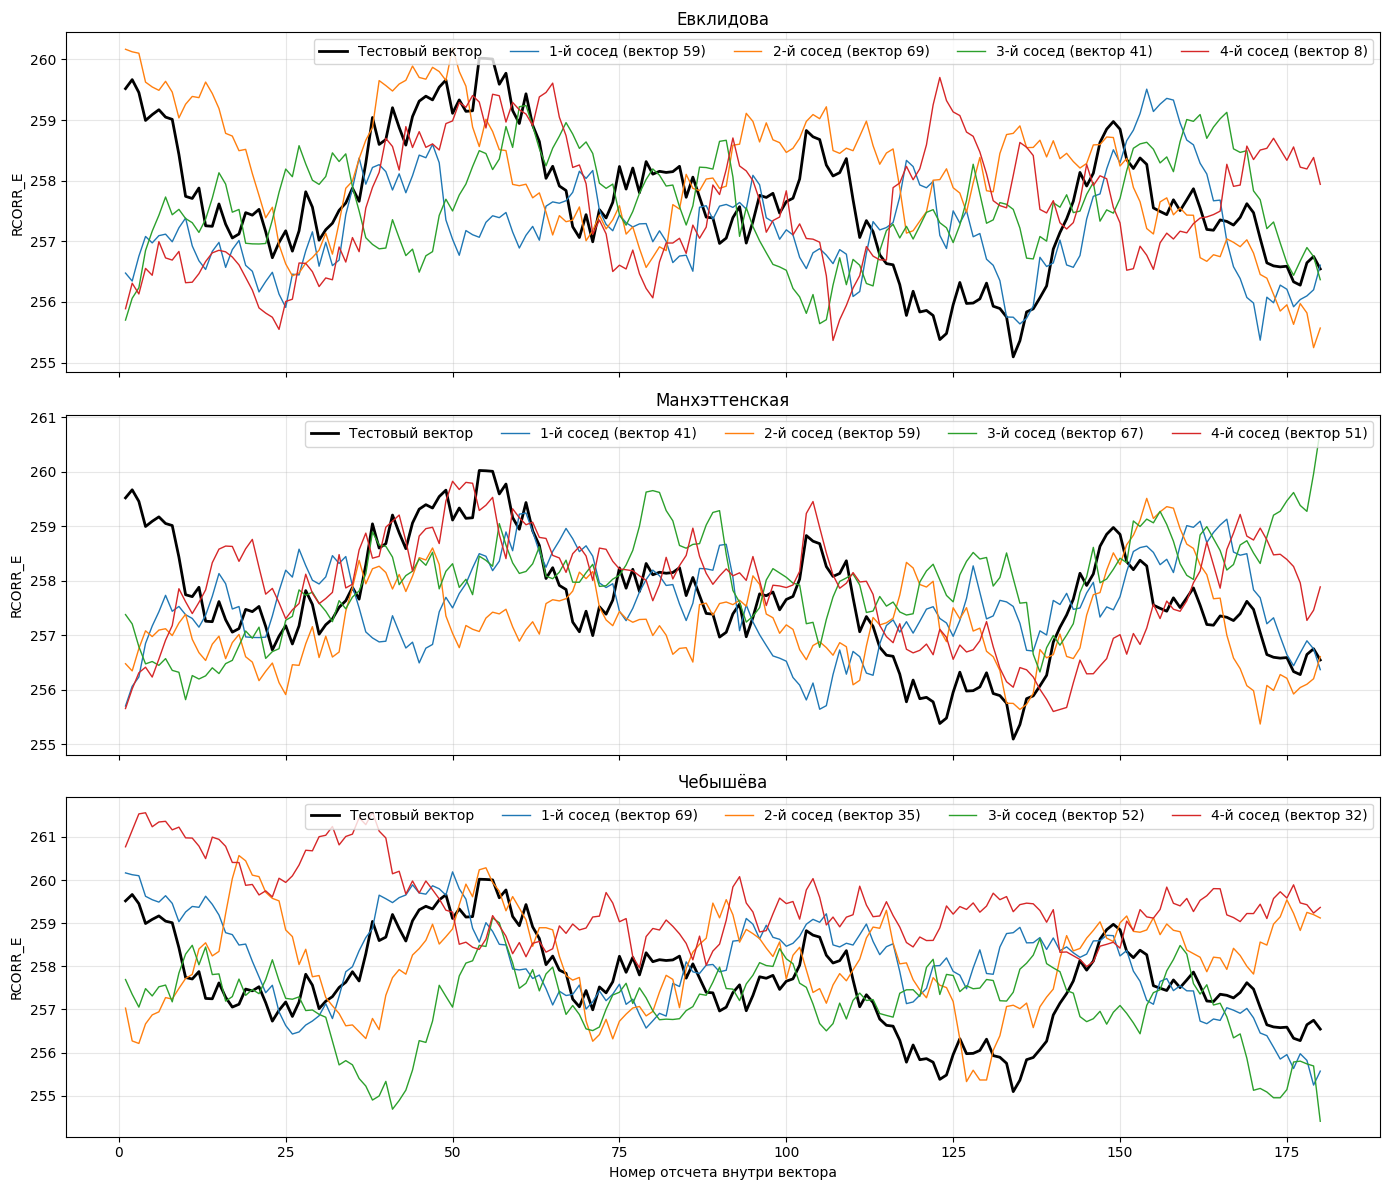

In [ ]:
window = 15
steps = np.arange(1, m + 1)

fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

for ax, metric_name in zip(axes, metric_functions):
    nearest_indices = neighbor_indices_by_metric[metric_name][:4]
    smoothed_test = pd.Series(test_vector).rolling(window, center=True, min_periods=1).mean()
    ax.plot(steps, smoothed_test, color="black", linewidth=2, label="Тестовый вектор")

    for rank in range(4):
        idx = nearest_indices[rank]
        smoothed = pd.Series(history_vectors[idx]).rolling(window, center=True, min_periods=1).mean()
        ax.plot(steps, smoothed, linewidth=1, label=str(rank + 1) + "-й сосед (вектор " + str(idx + 1) + ")")

    ax.set_title(metric_name)
    ax.set_ylabel("RCORR_E")
    ax.grid(True, alpha=0.3)
    ax.legend(ncol=5, loc="upper right")

axes[-1].set_xlabel("Номер отсчета внутри вектора")
plt.tight_layout()
plt.show()

#### 4. Прогноз по соседям

In [18]:
first_validation = len(vectors) // 2
error_blocks = {}

for query_idx in range(first_validation, len(vectors) - 1):
    query_vector = vectors[query_idx]
    candidates = vectors[:query_idx]
    continuations = vectors[1:query_idx + 1]
    actual_future = vectors[query_idx + 1]
    candidate_differences = candidates - query_vector

    for metric_name, metric_function in metric_functions.items():
        nearest_indices = np.argsort(metric_function(candidate_differences))
        for k in k_values:
            predicted = np.mean(continuations[nearest_indices[:k]], axis=0)
            error_blocks.setdefault((metric_name, k), []).append(actual_future - predicted)

    error_blocks.setdefault(("Среднее по ряду", 0), []).append(actual_future - np.mean(vectors[:query_idx + 1]))

accuracy_rows = []
for (name, k), blocks in error_blocks.items():
    errors = np.concatenate(blocks)
    accuracy_rows.append({
        "Метод": name,
        "k": k,
        "MAE": np.mean(np.abs(errors)),
        "RMSE": np.sqrt(np.mean(errors ** 2)),
    })

accuracy_df = pd.DataFrame(accuracy_rows)
display(accuracy_df.round(3))

knn_df = accuracy_df[accuracy_df["k"] > 0]
best = knn_df.loc[knn_df["RMSE"].idxmin()]
best_k = int(best["k"])
print("Лучшая комбинация:", best["Метод"], "k =", best_k, "RMSE =", round(best["RMSE"], 3))
print("Блоков в валидации:", len(range(first_validation, len(vectors) - 1)))

,Метод,k,MAE,RMSE
0,Евклидова,2,3.701,4.613
1,Евклидова,3,3.488,4.350
2,Евклидова,4,3.375,4.213
3,Манхэттенская,2,3.695,4.602
4,Манхэттенская,3,3.473,4.335
5,Манхэттенская,4,3.364,4.197
6,Чебышёва,2,3.715,4.637
7,Чебышёва,3,3.485,4.362
8,Чебышёва,4,3.396,4.255
9,Среднее по ряду,0,3.061,3.834


Лучшая комбинация: Манхэттенская k = 4 RMSE = 4.197
Блоков в валидации: 35


,"Евклидова, k=2","Евклидова, k=3","Евклидова, k=4","Манхэттенская, k=2","Манхэттенская, k=3","Манхэттенская, k=4","Чебышёва, k=2","Чебышёва, k=3","Чебышёва, k=4"
2018-11-10 00:00:00,259.770,256.940000,255.6375,255.925,259.193333,256.9025,258.705,257.040000,257.3525
2018-11-10 00:01:00,259.245,257.910000,258.6575,258.120,258.576667,257.7925,257.540,257.206667,257.3850
2018-11-10 00:02:00,253.060,254.746667,255.1200,255.790,258.450000,257.7275,255.840,255.223333,255.5025
2018-11-10 00:03:00,254.890,256.900000,257.0800,258.880,258.226667,258.9625,257.070,256.033333,256.0475
2018-11-10 00:04:00,251.585,253.186667,254.1575,253.750,255.563333,255.3250,255.250,257.666667,259.6825


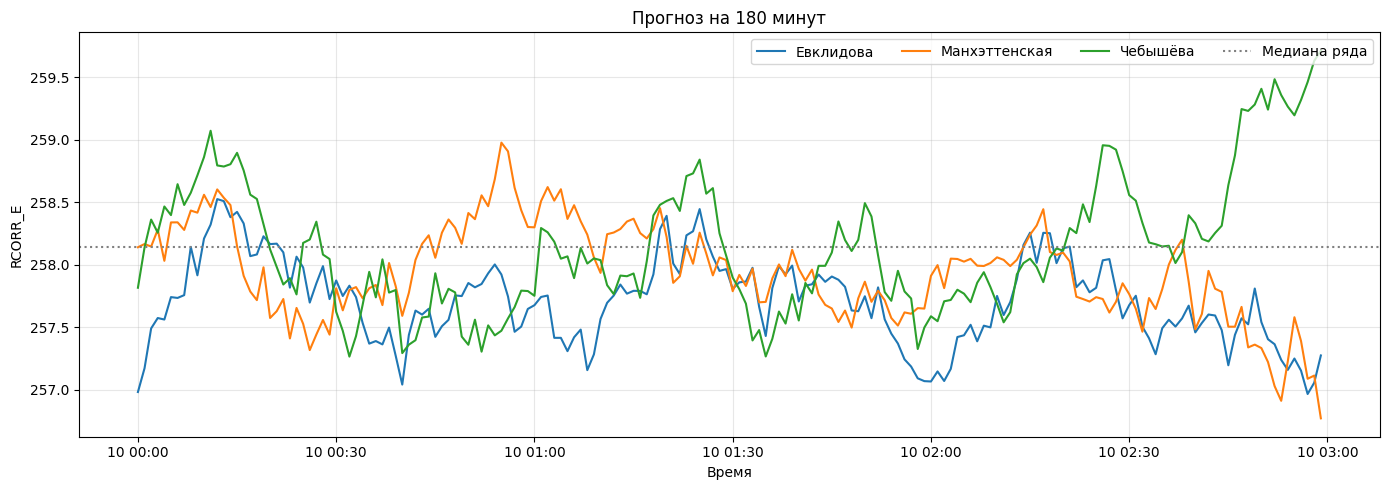

In [ ]:
candidates = vectors[:-1]
continuations = vectors[1:]
final_differences = candidates - vectors[-1]
future_index = pd.date_range(fixed_df.index.max() + pd.Timedelta(minutes=1), periods=m, freq="min")
forecasts = {}

for metric_name, metric_function in metric_functions.items():
    nearest_indices = np.argsort(metric_function(final_differences))
    for k in k_values:
        forecasts[(metric_name, k)] = np.mean(continuations[nearest_indices[:k]], axis=0)

forecast_df = pd.DataFrame({f"{name}, k={k}": prediction for (name, k), prediction in forecasts.items()},index=future_index,)
display(forecast_df.head())

smooth_window = 15
fig, ax = plt.subplots(figsize=(14, 5))

for metric_name in metric_functions:
    ax.plot(future_index, pd.Series(forecasts[(metric_name, best_k)], index=future_index).rolling(smooth_window, center=True, min_periods=1).mean(), linewidth=1.5, label=metric_name)

ax.axhline(median_value, color="gray", linestyle=":", label="Медиана ряда")
ax.set_title("Прогноз на 180 минут")
ax.set_xlabel("Время")
ax.set_ylabel("RCORR_E")
ax.grid(True, alpha=0.3)
ax.legend(ncol=4, loc="upper right")
plt.tight_layout()
plt.show()